# Affine Surrogates
## Training
Given function $f: \mathbb{R}^d \to \mathbb{R}$, and a cluster of points $X \in \mathbb{R}^{d \times N}$, we define the centered points $X_c = X - \mu \mathbf{1}_{1 \times N}$ and the centered function values $F_c = F - f_\mu \mathbf{1}_{1 \times N}$, where $F \in \mathbb{R}^{1 \times N}$ represents the function values at the cluster points, $\mu \in \mathbb{R}^{d \times 1}$ is the cluster center, and $f_\mu \in \mathbb{R}$ is the average of the function values in the cluster.

A linear model is fit, given by:
$$\hat{f}(x) = A x + b$$
where $A \in \mathbb{R}^{1 \times d}$ and $b \in \mathbb{R}$ are found by solving the normal equations (with Tikhonov regularization), using batched `np.linalg.solve`:
$$\left( X_c X_c^T + \lambda I \right) A^T = X_c F_c^T$$
$$b = f_\mu - A \mu$$

$\lambda$ is defined as $\lambda = 10^{-8} \cdot \text{max\_eigenvalue}(X_c X_c^T)$ to ensure numerical stability. Here, since $X_c X_c^T$ is a positive semi-definite matrix, its eigenvalues are non-negative, which implies $\lambda_\text{max} = \mathcal{O}(\sum_i \lambda_i) = \mathcal{O}(\text{Tr}(X_c X_c^T))$. Hence, instead of computing the eigenvalues of the symmetric matrix $X_c X_c^T$, we can compute the trace which is much cheaper and still provides a good scaling for $\lambda$.

## Inference
For a query point $x_q$, we find the cluster center closest to $x_q$ in $\| \cdot \|_{H}$ Hessian norm. Then using the linear model of that cluster, we compute the predicted function:
$$\hat{f}(x_q; A_{k}, b_{k}) = A_{k} x_q + b_{k}$$


## Taylor Surrogates: Estimation of $H^{-1}$ from Cluster Covariance
When using Taylor surrogates, we have access to analytical gradients. We estimate the Hessian inverse $H^{-1}$ using the spatial covariance of a subset of cluster points $X_S \subset X$ whose errors are smallest with respect to the first-order Taylor expansion:
$$e(x) = f(x) - \hat{f}(x; \mu) = f(x) - \left( f(\mu) + \nabla f(\mu)^T (x - \mu) \right)$$

By Taylor's expansion:
$$f(x) = f(\mu) + \nabla f(\mu)^T (x - \mu) + \frac{1}{2} (x - \mu)^T H (x - \mu) + \mathcal{O}(\|x - \mu\|^3)$$

Substituting this into the error equation:
$$e(x) \approx \frac{1}{2} (x - \mu)^T H (x - \mu)$$

When we sort the cluster points and select the subset $X_S$ minimizing $|e(x)|$, we are strictly filtering for points where $(x - \mu)^T H (x - \mu) \approx 0$. Geometrically, this isolates the principal directions where the function exhibits minimum curvature.

The covariance of these points, $\Sigma_S = \frac{1}{|X_S|} \sum_{x \in X_S} (x - \mu)(x - \mu)^T$, maximizes the variance along these flat directions. For a distribution bounded by a quadratic level set, $\{x : (x - \mu)^T H (x - \mu) \leq c\}$, this sample covariance is proportionally inverse to the quadratic form itself:
$$\Sigma_S \propto H^{-1}$$
The subsequent eigendecomposition of $\Sigma_S$ gives the dominant eigenvectors of $H$, allowing us to bisect the cluster along the optimal hyperplanes that capture the maximum non-linear error, ensuring efficient and effective recursive partitioning.

## Issues with Affine Surrogates
With affine surrogates, analytical gradients are unavailable, so the surrogate evaluates standard affine error:
$$e(x) = f(x) - \hat{f}(x; A, b) = f(x) - (A x + b)$$

Standard least-squares optimization minimizes the global variance across the entire spatial extent of the cluster. To achieve this, the solver absorbs the average effect of the function's quadratic curvature into the intercept term $b$, pulling the plane vertically away from $f(\mu)$ (i.e., $b \neq f(\mu) - A\mu$). Also, the slope $A$ tilts to slice *through* the function manifold, creating a **secant plane** rather than a tangent plane.

Because the surrogate is a secant plane, the points minimizing $|e(x)| \approx 0$ do not lie at the bottom of the local extrema. Instead, they constitute the intersection ring where the secant plane geometrically intersects the curved function manifold up its walls. 

Taking the covariance of this hollow intersection ring yields an arbitrary matrix without the principal directional information of the manifold. Hence, $\Sigma_S \not\propto H^{-1}$, the splitting directions become suboptimal, and the algorithm recursively fragments clusters, artificially bloating the total cluster count.


## Fix - Anchoring the Affine Surrogate to the Cluster Center
To accurately estimate $H^{-1}$ without analytical gradients, we must force the affine fit to behave identically to a first-order Taylor expansion. We achieve this by anchoring the surrogate directly to the cluster center $(\mu, f(\mu))$, and hence, removing the free intercept parameter $b$. The model then becomes:
$$\hat{f}_{\text{anchored}}(x; \mu) = f(\mu) + A_{\text{tangent}} (x - \mu)$$

Let $\Delta X_{\text{core}} \in \mathbb{R}^{m \times d}$ and $\Delta F_{\text{core}} \in \mathbb{R}^{m}$ represent a localized subset of the $m$ points nearest to $\mu$, explicitly shifted to the true centroid anchor:
$$\Delta X_{\text{core}} = X_{\text{core}} - \mathbf{1}_{m} \mu$$
$$\Delta F_{\text{core}} = F_{\text{core}} - \mathbf{1}_{m} f(\mu)$$

We find  $A_{\text{tangent}}$ by solving:
$$(\Delta X_{\text{core}}^T \Delta X_{\text{core}} + \lambda I) A_{\text{tangent}}^T = \Delta X_{\text{core}}^T \Delta F_{\text{core}}$$

Since plane is fixed to $(\mu, f(\mu))$, it cannot translate to absorb global curvature. By restricting the fit to the closest points ($m \ll N$), the maximum spatial radius $r = \|\Delta x_i\|$ shrinks. Substituting the true Taylor expansion $\Delta F_{\text{core}} = \Delta X_{\text{core}} \nabla f(\mu) + \mathcal{O}(r^2)$ into the normal equations yields:
$$A_{\text{tangent}}^T = (\Delta X_{\text{core}}^T \Delta X_{\text{core}})^{-1} \Delta X_{\text{core}}^T \left( \Delta X_{\text{core}} \nabla f(\mu) + \mathcal{O}(r^2) \right)$$
$$A_{\text{tangent}}^T = \nabla f(\mu) + \mathcal{O}(r^2)$$

As the local neighborhood tightens ($r \to 0$), the anchored slope converges exactly to the analytical gradient: $\lim_{r \to 0} A_{\text{tangent}} = \nabla f(\mu)^T$.

By evaluating the error of the *entire* cluster $X$ using this local tangent proxy ($e(x) = f(x) - f(\mu) - A_{\text{tangent}}(x - \mu)$), the residual once again isolates the pure second-order curvature $\frac{1}{2} \Delta x^T H \Delta x$. This restores the geometric integrity of the $X_S$ subset, allowing $\Sigma_S$ to correctly map $H^{-1}$.


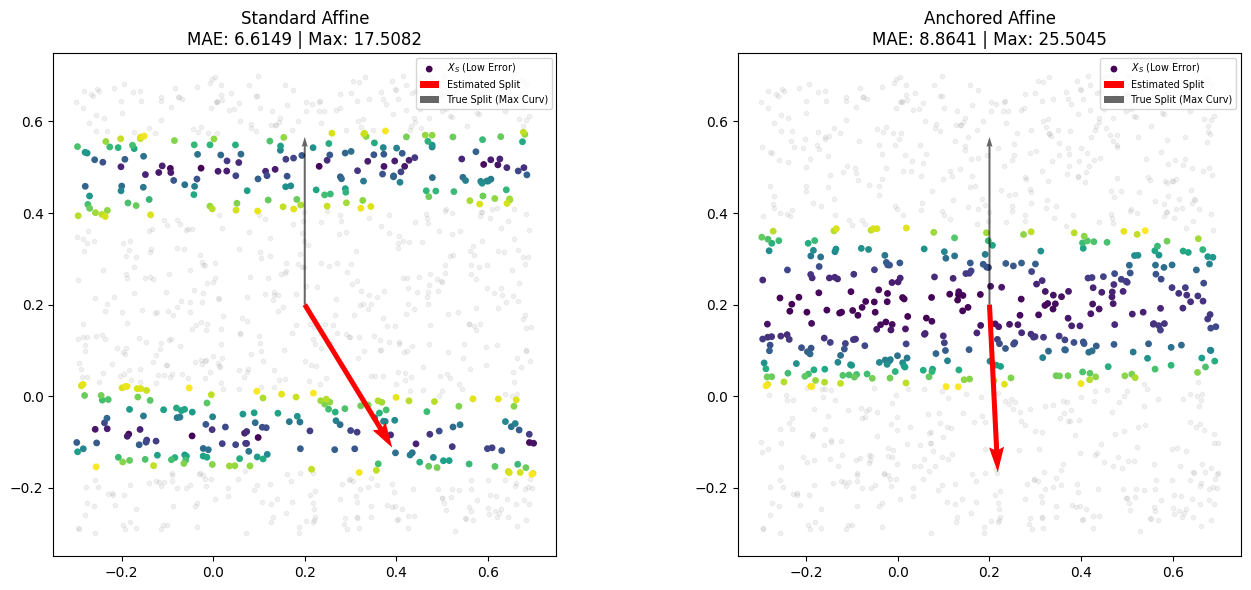

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

# 1. Setup Problem symbolically
x_sym, y_sym = sp.symbols("x y")
f_sym = x_sym**2 + 100 * y_sym**2 + 0 * x_sym * y_sym

# 2. Create the numerical proxy using lambdify
f_np = sp.lambdify((x_sym, y_sym), f_sym, "numpy")


def f(X):
    """
    Evaluates the symbolic function numerically on an (N, 2) array.
    """
    return f_np(X[:, 0], X[:, 1])


# Calculate Hessian Matrix symbolically
H_sym = sp.hessian(f_sym, (x_sym, y_sym))


def get_true_splitting_dir(mu_val):
    _h_sub = H_sym.subs({x_sym: mu_val[0], y_sym: mu_val[1]})
    H_eval = np.array(_h_sub).astype(np.float64)
    _, evecs = np.linalg.eigh(H_eval)
    # Return Largest eigenvalue (Most Curvature)
    return evecs[:, -1]


def get_split_dir(X_sub, mu_sub):
    cov = np.cov((X_sub - mu_sub).T)
    _, evecs = np.linalg.eigh(cov)
    # Return Smallest variance (Most Curvature Proxy)
    return evecs[:, 0]


np.random.seed(0)
N = 1000
mu = np.array([[0.2, 0.2]])
X = mu + np.random.uniform(-0.5, 0.5, size=(N, 2))

F = f(X)
f_mu = f(mu)[0]  # Extract scalar from returned array

N_SMALLEST = N // 3

# True splitting direction
v_true = get_true_splitting_dir(mu[0])

# --- MODE A: STANDARD AFFINE ---
X_c = X - np.mean(X, axis=0)
F_c = F - np.mean(F)
A_std = np.linalg.solve(X_c.T @ X_c, X_c.T @ F_c)
b_std = np.mean(F) - A_std @ np.mean(X, axis=0)
err_std = np.abs(F - (X @ A_std + b_std))

# --- MODE B: ANCHORED AFFINE ---
dist = np.linalg.norm(X - mu, axis=1)
core_idx = np.argsort(dist)[:N_SMALLEST]
dX_core = X[core_idx] - mu
dF_core = F[core_idx] - f_mu
A_anch = np.linalg.solve(dX_core.T @ dX_core, dX_core.T @ dF_core)
err_anch = np.abs(F - (f_mu + (X - mu) @ A_anch))


# Calculate Global Error Metrics
mae_std = np.mean(err_std)
max_std = np.max(err_std)

mae_anch = np.mean(err_anch)
max_anch = np.max(err_anch)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Zip the errors and the pre-calculated metrics into the loop
plot_configs = [
    (err_std, "Standard Affine", mae_std, max_std),
    (err_anch, "Anchored Affine", mae_anch, max_anch),
]

for ax, (err, name, mae, l_inf) in zip(axes, plot_configs):
    # Select the subset of points with the lowest error
    idx_s = np.argsort(err)[:N_SMALLEST]
    X_s = X[idx_s]

    ax.scatter(X[:, 0], X[:, 1], c="gray", alpha=0.1, s=10)
    sc = ax.scatter(
        X_s[:, 0],
        X_s[:, 1],
        c=err[idx_s],
        cmap="viridis",
        s=15,
        label="$X_S$ (Low Error)",
    )

    v_est = get_split_dir(X_s, mu)
    ax.quiver(
        mu[0, 0],
        mu[0, 1],
        v_est[0],
        v_est[1],
        color="red",
        scale=3,
        width=0.01,
        label="Estimated Split",
    )

    ax.quiver(
        mu[0, 0],
        mu[0, 1],
        v_true[0],
        v_true[1],
        color="black",
        scale=3,
        width=0.004,
        alpha=0.6,
        label="True Split (Max Curv)",
    )

    # Updated Title with Metrics
    ax.set_title(f"{name}\nMAE: {mae:.4f} | Max: {l_inf:.4f}")
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize="x-small")

plt.tight_layout()
plt.show()